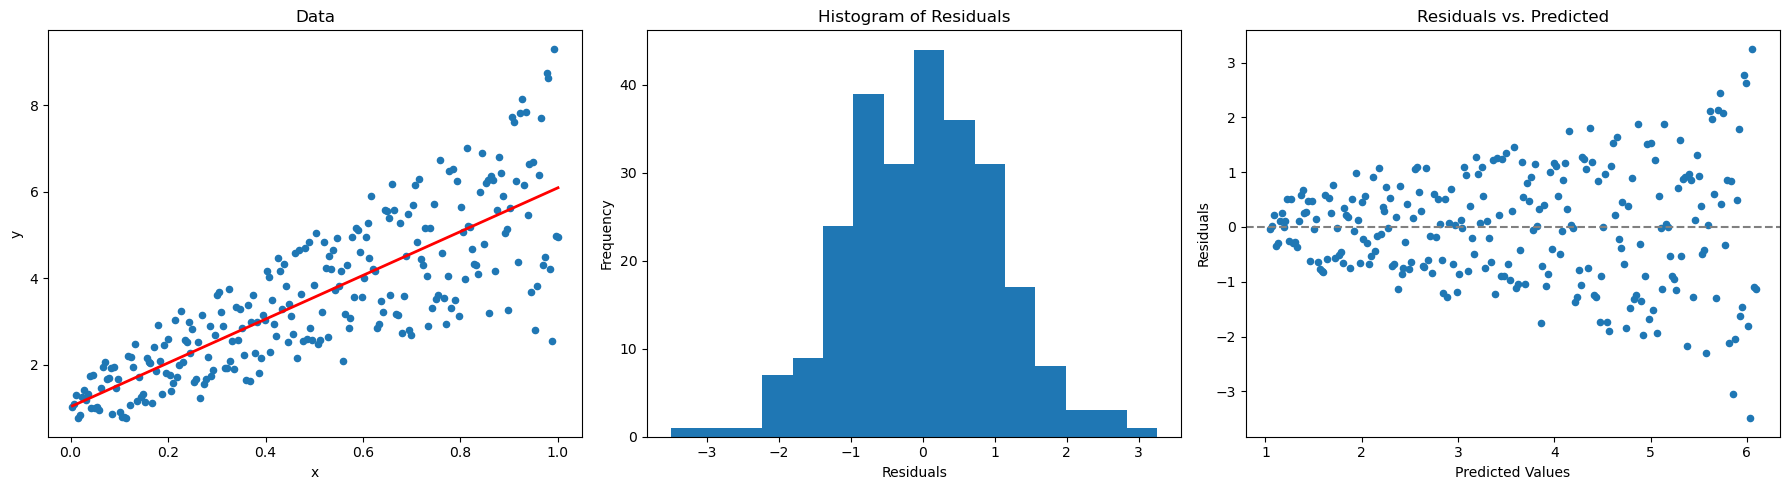

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Set seed for reproducibility and define variables
# R: set.seed(17)
# R: n <- 256
np.random.seed(17)
n = 256

# 2. Generate the data
# R: x <- (1:n)/n
x = np.arange(1, n + 1) / n

# R: e <- rnorm(n, sd=1)
e = np.random.normal(loc=0, scale=1, size=n)

# R: i <- order(runif(n, max=dnorm(e)))
# This line in R intentionally creates heteroscedasticity (non-constant variance)
# by reordering the errors.
dnorm_e = norm.pdf(e)
random_uniforms = np.random.uniform(low=0, high=dnorm_e)
i = np.argsort(random_uniforms)

# R: y <- 1 + 5 * x + e[rev(i)]
# We reverse the sorted indices `i` to apply the reordered errors.
# `i[::-1]` is the Python way to reverse an array.
y = 1 + 5 * x + e[i[::-1]]

# 3. Perform Linear Regression
# It's good practice to use a pandas DataFrame for statsmodels
df = pd.DataFrame({'x': x, 'y': y})

# R: fit <- lm(y ~ x)
fit = smf.ols('y ~ x', data=df).fit()

# You can print a summary similar to R's summary(fit)
# print(fit.summary())

# 4. Create the plots
# R: par(mfrow=c(1,3))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Data with regression line
# R: plot(x,y, main="Data", cex=0.8)
# R: abline(coef(fit), col="Red")
axes[0].scatter(df['x'], df['y'], s=20) # s is marker size, like cex
axes[0].plot(df['x'], fit.predict(), color='red', linewidth=2)
axes[0].set_title("Data")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

# Plot 2: Histogram of residuals
# R: hist(residuals(fit), main="Residuals")
axes[1].hist(fit.resid, bins='auto')
axes[1].set_title("Histogram of Residuals")
axes[1].set_xlabel("Residuals")
axes[1].set_ylabel("Frequency")

# Plot 3: Residuals vs. Predicted values
# R: plot(predict(fit), residuals(fit), cex=0.8, main="Residuals vs. Predicted")
axes[2].scatter(fit.fittedvalues, fit.resid, s=20)
axes[2].axhline(y=0, color='grey', linestyle='--') # Add a horizontal line at 0
axes[2].set_title("Residuals vs. Predicted")
axes[2].set_xlabel("Predicted Values")
axes[2].set_ylabel("Residuals")


# Display the plots
plt.tight_layout()
plt.show()